# This provides a starting code for SMOTE [tabular data] to increase the number of sampes of the minority class and create a balanced data set

In [13]:
# ---------------------------------------------------------------
# 1. IMPORT THE LIBRARIES
# ---------------------------------------------------------------
# A library contains ready-made Python tools.
# pandas reads tables, NumPy handles numbers and matplotlib makes plots.
# scikit-learn helps us prepare our data without writing the maths.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer


In [15]:
# ---------------------------------------------------------------
# 2. LOAD AND INSPECT THE DATA
# ---------------------------------------------------------------
# Each ROW is an observation from a simulated city sensor system.
# The sensor columns contain the measurements we will use as inputs.
# Humidity_Level is the category we want to predict.

df = pd.read_csv("simple_tabular_training_data.csv")
print("Dataset size:", df.shape)
print(df.head())



Dataset size: (1020, 8)
        City  sensor_01  sensor_02  sensor_03  sensor_04  sensor_05  \
0  Cambridge      75.76      67.33      18.76      84.26      46.86   
1  Edinburgh      61.95      53.81      48.45      59.42      36.41   
2  Liverpool      34.36      27.82      66.48      21.71      32.50   
3  Liverpool      82.45      69.96      12.80      95.82      40.27   
4     London      46.01      35.40      47.35      48.14      39.48   

   sensor_06 Humidity_Level  
0      42.83           High  
1      42.22       Moderate  
2      36.59            Low  
3      42.40           High  
4      20.13       Moderate  


In [16]:
# ---------------------------------------------------------------
# 3. CHOOSE INPUT FEATURES (X) AND TARGET LABELS (y)
# ---------------------------------------------------------------
# X = the information we use to make a prediction (sensor readings).
# y = the correct answer we want the model to learn (humidity class).
# City identifies where the reading came from. It is NOT a sensor.
# We remove rows that have no answer (missing Humidity_Level).
# We exclude City and the answer itself from X to avoid leakage.

df = df.dropna(subset=["Humidity_Level"]).copy()
exclude = ["City", "Humidity_Level"]
X = df.drop(columns=exclude)
y = df["Humidity_Level"]
groups = df["City"]   # Only used in splitting Option B

print("\nInput columns:", X.columns.tolist())
print("\nMissing sensor values:\n", X.isna().sum())
print("\nHumidity categories:\n", y.value_counts())

# A computer works more easily with numbers than with text labels.
# LabelEncoder turns categories such as 'Low' into integer class IDs.
encoder = LabelEncoder()
y = encoder.fit_transform(y)
print("\nClass names:", encoder.classes_)



Input columns: ['sensor_01', 'sensor_02', 'sensor_03', 'sensor_04', 'sensor_05', 'sensor_06']

Missing sensor values:
 sensor_01    0
sensor_02    0
sensor_03    0
sensor_04    0
sensor_05    0
sensor_06    0
dtype: int64

Humidity categories:
 Humidity_Level
Moderate    388
Low         319
High        313
Name: count, dtype: int64

Class names: ['High' 'Low' 'Moderate']


In [17]:
# ---------------------------------------------------------------
# 4. SPLIT INTO TRAINING, VALIDATION AND TEST SETS
# ---------------------------------------------------------------
# Training: the examples used for learning.
# Validation: examples used to compare model settings while developing.
# Test: examples held back for a final check on unseen observations.
#
# CHOOSE ONE OPTION BELOW. Do NOT run both.
# To switch methods, add # to every active line in Option A,
# then remove the # symbols from the code lines in Option B.
#
# OPTION A — RANDOM SPLIT (ACTIVE)
# Easier for beginners. Approximately 64% train, 16% validation,
# 20% test. stratify keeps class proportions approximately similar.
# Readings from the same city MAY appear in different sets.

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42, stratify=y_train
)

# OPTION B — GROUPED BY CITY (COMMENTED OUT)
# A city cannot appear in more than one set. This asks a harder question:
# Can the model make predictions for cities it never saw in training?
# The class proportions are NOT guaranteed to match across sets.
#
# splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
# train_ids, test_ids = next(splitter.split(X, y, groups=groups))
# X_train = X.iloc[train_ids]
# X_test = X.iloc[test_ids]
# y_train = y[train_ids]
# y_test = y[test_ids]
#
# splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=21)
# train_ids2, val_ids = next(
#     splitter.split(X_train, y_train, groups=groups.iloc[train_ids])
# )
# X_val = X_train.iloc[val_ids]
# y_val = y_train[val_ids]
# X_train = X_train.iloc[train_ids2]
# y_train = y_train[train_ids2]

print("\nTraining rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))


Training rows: 652
Validation rows: 164
Test rows: 204


In [18]:
# ---------------------------------------------------------------
# 5. FILL IN MISSING SENSOR READINGS
# ---------------------------------------------------------------
# A missing reading is shown as NaN. Machine learning algorithms
# generally need numerical values rather than gaps.
# We fill gaps with the MEDIAN value of that sensor column.
# IMPORTANT: calculate medians from TRAINING data only. Using the
# validation or test data to calculate them would cause data leakage.
# This example assumes no sensor column is entirely empty in training.

imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train)
X_val = imputer.transform(X_val)
X_test = imputer.transform(X_test)


In [19]:
# ---------------------------------------------------------------
# 6. SCALE SENSOR READINGS
# ---------------------------------------------------------------
# Some sensors have much larger numbers than others. StandardScaler
# puts features on comparable scales, which helps a neural network
# learn and makes SMOTE's distance calculations more meaningful.
# Again, we learn the scaling from TRAINING data only.

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)



In [20]:
# ---------------------------------------------------------------
# 7. BALANCE THE TRAINING DATA WITH SMOTE
# ---------------------------------------------------------------
# If one humidity class has fewer examples, a model may pay it less
# attention. SMOTE creates additional SYNTHETIC training examples
# for minority classes by interpolating between nearby examples.
# We do NOT apply SMOTE to validation or test data: these need to
# remain unchanged so we can evaluate on realistic observations.
# If this library is missing, install once: pip install imbalanced-learn

from imblearn.over_sampling import SMOTE

before = pd.Series(encoder.inverse_transform(y_train)).value_counts()
print("\nTraining classes BEFORE SMOTE:\n", before)

# k_neighbors=3 requires at least four training examples per class.
smote = SMOTE(random_state=42, k_neighbors=3)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

after = pd.Series(encoder.inverse_transform(y_train_smote)).value_counts()
print("\nTraining classes AFTER SMOTE:\n", after)



Training classes BEFORE SMOTE:
 Moderate    248
Low         204
High        200
Name: count, dtype: int64

Training classes AFTER SMOTE:
 Low         248
Moderate    248
High        248
Name: count, dtype: int64


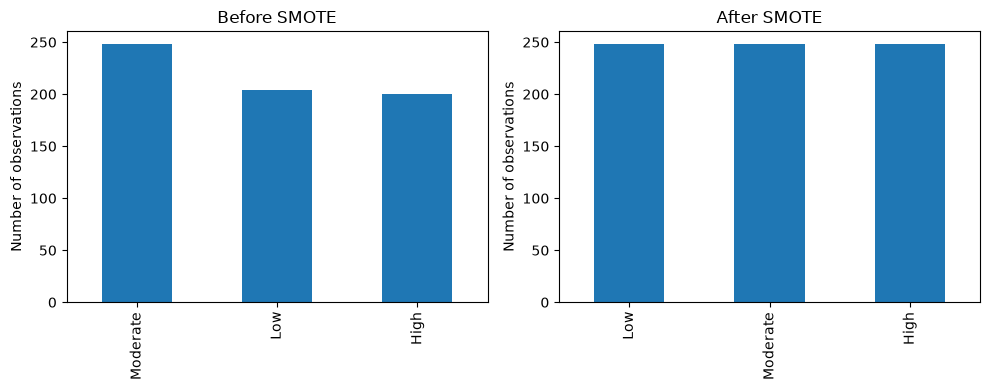


Final data shapes:
Training after SMOTE: (744, 6)
Validation: (164, 6)
Test: (204, 6)


In [21]:
# ---------------------------------------------------------------
# 8. COMPARE CLASS COUNTS BEFORE AND AFTER SMOTE
# ---------------------------------------------------------------
# A simple bar chart makes it easy to see what has changed.
# Only the training data has been balanced; the other sets are
# still untouched.

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
before.plot.bar(ax=axes[0], title="Before SMOTE")
after.plot.bar(ax=axes[1], title="After SMOTE")
axes[0].set_ylabel("Number of observations")
axes[1].set_ylabel("Number of observations")
plt.tight_layout()
plt.show()

print("\nFinal data shapes:")
print("Training after SMOTE:", X_train_smote.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)